# Clustering

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans as KMeans2

Clustering is an unsupervised learning method. We use it in a setting where there are no labels in the data, but we still want to discover patterns or groups of data points. Clustering algorithms find these groups (called clusters) using a measure of similarity or distance.

## K-Means

**K-Means** is a simple clustering algorithm that tries to assign the data to $K$ clusters where the number of clusters is predetermined.

The general algorithms is as follows:
1. Randomly assign $K$ cluster centroids (meaning pick $K$ points randomly and let their coordinates be the coordinates of the centroids)
2. Assign each data point to the closes centroid based on some distance measure
3. For each cluster, move the centroid to the center (average) location in its cluster
4. Repeat 1-3 until the centroids stop moving

This algorithm suffers from a small problem - since the centroids are initialized randomly, we will arrive at different clusterings depending on what initialization we happen to get. This means that **K-Means** is not guaranteed to arrive at the optimal solution. To mitigate this, we effectively run the algorithm multiple times, initializing differently each time, and then pick the result with the lowest cost $J$.

The cost function $J$ can be defined as:

$$
J = \sum_{i=1}^k \sum_{x \in C_i} || x - \mu_i ||^2
$$

where $k$ is the number of clusters, $C_i$ is the set of data points in cluster $i$, $\mu_i$ is the centroid (mean) of cluster $i$ and $|| x - \mu_i ||^2$ is the squared Euclidean distance between a point $x$ and its cluster centroid.

In [71]:
class KMeans:
    def __init__(self, n_clusters, n_init=10, eps=1e-4, max_iter=300, seed=None):
        self.n_clusters = n_clusters
        self.n_init = n_init
        self.eps = eps
        self.max_iter = max_iter
        self.rng = np.random.default_rng(seed)

    def fit(self, X):
        best_cost = np.inf
        best_clusters = None
        for i in range(self.n_init):
            cost, clusters = self._fit(X)
            if cost < best_cost:
                best_cost = cost
                best_clusters = clusters
        self.clusters = best_clusters
        return self

    def _fit(self, X):
        n_samples = X.shape[0]
        indices = self.rng.choice(n_samples, size=self.n_clusters, replace=False)
        centroids = X[indices]
        dist = np.linalg.norm(X[:, None, :] - centroids[None, :, :], axis=2)
        
        clusters = np.argmin(dist, axis=1)
        best_clusters = clusters
        best_cost = self._cost(X, centroids, clusters)

        i = 0
        while True:
            centroids = np.zeros((self.n_clusters, X.shape[1]))
            counts = np.bincount(clusters, minlength=self.n_clusters)    
            np.add.at(centroids, clusters, X)
            centroids = centroids / counts[:, None]
            dist = np.linalg.norm(X[:, None, :] - centroids[None, :, :], axis=2)
            clusters = np.argmin(dist, axis=1)
            cost = self._cost(X, centroids, clusters)
            if cost < best_cost:
                best_cost = cost
                best_clusters = clusters
            if np.abs(best_cost - cost) < self.eps:
                break
            if (i >= self.max_iter if self.max_iter is not None else False):
                break
            i += 1
        return best_cost, best_clusters

    def _cost(self, X, centroids, clusters):
        return np.sum(np.linalg.norm(X - centroids[clusters], axis=1) ** 2)

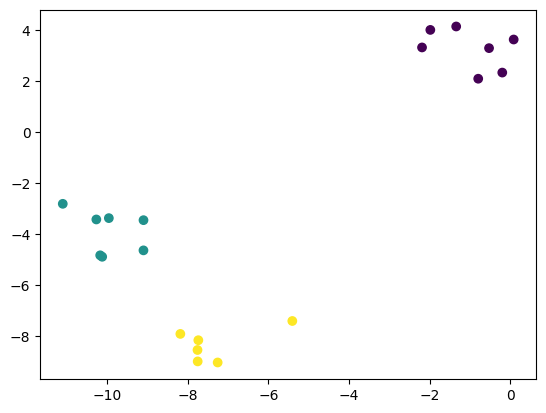

In [72]:
X, y = make_blobs(n_samples=20, n_features=2, centers=None, cluster_std=1.0, center_box=(-10.0, 10.0), shuffle=True, random_state=1, return_centers=False)
plt.scatter(X[:, 0], X[:, 1], c=y)

In [73]:
kmeans = KMeans(n_clusters=3).fit(X)
kmeans2 = KMeans2(n_clusters=3, init='random', n_init=10, max_iter=300, tol=0.0001).fit(X)

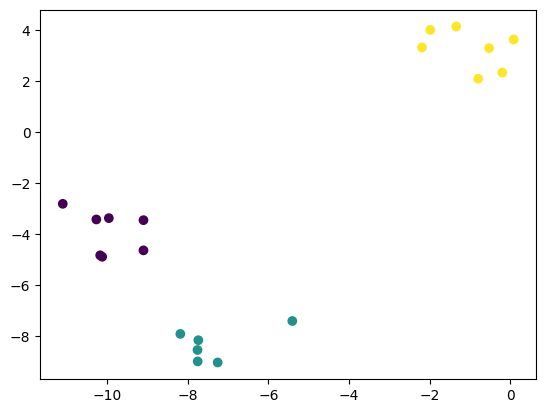

In [74]:
plt.scatter(X[:, 0], X[:, 1], c=kmeans.clusters)

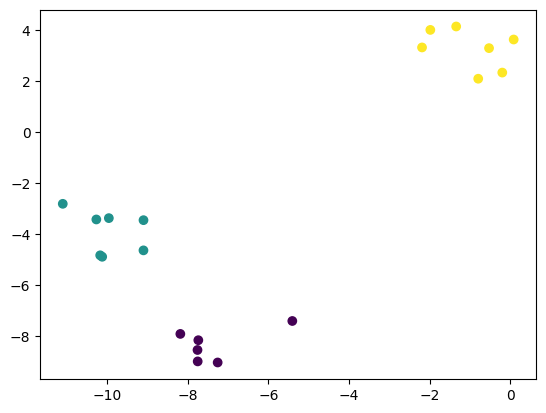

In [75]:
plt.scatter(X[:, 0], X[:, 1], c=kmeans2.labels_)

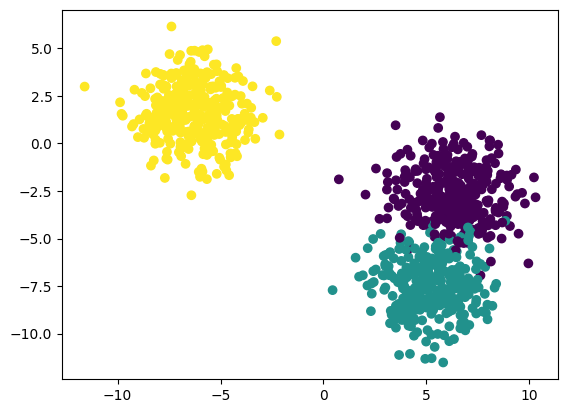

In [76]:
X, y = make_blobs(n_samples=1000, n_features=2, centers=None, cluster_std=1.5, center_box=(-8.0, 8.0), shuffle=True, random_state=6, return_centers=False)
plt.scatter(X[:, 0], X[:, 1], c=y)

In [77]:
kmeans = KMeans(n_clusters=3, seed=1).fit(X)
kmeans2 = KMeans2(n_clusters=3, init='random', n_init=10, max_iter=300, tol=0.0001, random_state=1).fit(X)

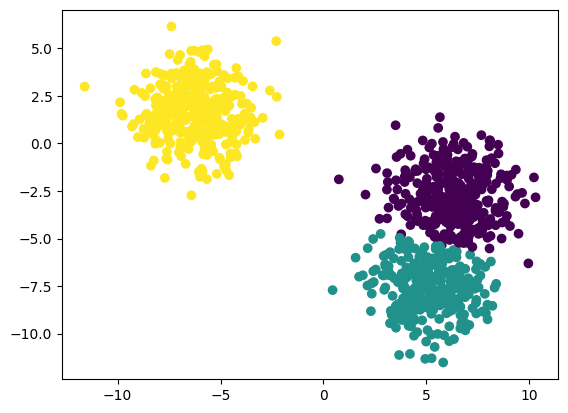

In [78]:
plt.scatter(X[:, 0], X[:, 1], c=kmeans.clusters)

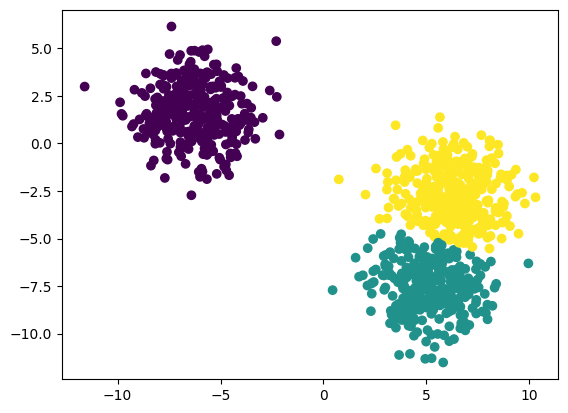

In [79]:
plt.scatter(X[:, 0], X[:, 1], c=kmeans2.labels_)